In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [59]:
df = pd.read_csv("diabetes_risk.csv")

TARGET = "diabetes_risk"
TARGET_ORDER = ["Low", "Moderate", "High"]

### Gambaran Umum Data

In [60]:
df.head()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  object 
 3   city                      15000 non-null  object 
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  object 
 6   physical_activity_level   15000 non-null  object 
 7   diet_type                 15000 non-null  object 
 8   smoking_status            14528 non-null  object 
 9   alcohol_consumption       11212 non-null  object 
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null  float64
 14  blood_

In [62]:
print("Jumlah baris, kolom:", df.shape)
print("Baris duplikat:", df.duplicated().sum())
print("Patient_id unik?", df["patient_id"].is_unique)

Jumlah baris, kolom: (15000, 19)
Baris duplikat: 0
Patient_id unik? True


In [63]:
df.isna().sum()

patient_id                     0
age                            0
gender                         0
city                           0
bmi                            0
family_history_diabetes        0
physical_activity_level        0
diet_type                      0
smoking_status               472
alcohol_consumption         3788
hours_sleep_per_night          0
stress_level                   0
fasting_blood_sugar            0
hba1c_level                    0
blood_pressure_systolic        0
blood_pressure_diastolic       0
waist_circumference_cm         0
income_bracket               463
diabetes_risk                  0
dtype: int64

**Interpretasi**: Terdapat 15.000 baris dan 19 kolom (satu baris = satu pasien). Tidak ada duplikat dan patient_id unik, sehingga kolom ini hanya sebagai pengenal dan harus di-drop sebelum modeling agar model tidak belajar dari nomor urut. Tiga kolom memiliki missing values: smoking_status (14.528), alcohol_consumption (11.212), dan income_bracket (14.537).

### Tipe Kolom dan Statistik Deskriptif

In [64]:
num_cols = df.select_dtypes(include="number").columns.drop("patient_id").tolist()
cat_cols = df.select_dtypes(exclude="number").columns.drop(TARGET).tolist()
print("Numerik    :", num_cols)
print("Kategorikal:", cat_cols)

Numerik    : ['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm']
Kategorikal: ['gender', 'city', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption', 'income_bracket']


In [65]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,15000.0,44.333667,10.383753,18.0,38.0,45.0,52.0,80.0
bmi,15000.0,23.062260,4.046391,15.0,20.1,22.7,25.6,40.8
hours_sleep_per_night,15000.0,7.309860,1.109372,3.0,6.7,7.0,8.0,12.0
stress_level,15000.0,5.941200,2.148406,1.0,4.0,6.0,7.0,10.0
fasting_blood_sugar,15000.0,168.789933,38.365822,72.0,145.0,165.0,189.0,400.0
hba1c_level,15000.0,6.878387,0.843276,4.8,6.3,6.8,7.3,13.4
blood_pressure_systolic,15000.0,139.496200,12.660785,80.0,130.0,140.0,150.0,200.0
blood_pressure_diastolic,15000.0,86.256933,8.386529,50.0,80.0,88.0,90.0,120.0
waist_circumference_cm,15000.0,100.207933,10.760331,73.2,92.5,99.3,106.9,148.2


In [66]:
df[cat_cols].describe().T

,count,unique,top,freq
gender,15000,3,Male,7664
city,15000,18,Mumbai,2243
family_history_diabetes,15000,2,No,9756
physical_activity_level,15000,3,Active,5100
diet_type,15000,4,Non-Vegetarian,8195
smoking_status,14528,3,Never,10119
alcohol_consumption,11212,3,Never,5616
income_bracket,14537,3,Middle,7305


**Interpretasi**: Terdapat 9 fitur numerik dan 8 kategorikal. stress_level berupa angka tetapi termasuk skala ordinal 1–10, sedangkan city merupakan nominal dengan 18 level. 

Semua rentang kolom masih masuk akal secara fisiologis: usia 18–80, BMI 15–40,8, tidur 3–12 jam, sistolik 80–200, dan diastolik 50–120. 

Rata-rata FBS (168,8) dan HbA1c (6,88) jauh di atas batas normal (di bawah 100 dan di bawah 5,7), jadi sampel ini bukan populasi umum yang sehat.

Mean dan median sebagian besar kolom hampir sama, sedangkan FBS (168,8 vs 165) dan HbA1c (6,88 vs 6,8) memiliki mean sedikit di atas median, yang mengindikasikan kemiringan ke kanan (dikonfirmasi di bagian univariate fitur numerik: skew 0,85 dan 0,88).

### Validasi Kualitas Data

In [92]:
bp_invalid = df[df["blood_pressure_diastolic"] >= df["blood_pressure_systolic"]]
print("Diastolik >= sistolik          :", len(bp_invalid), "baris")
display(bp_invalid[["patient_id", "blood_pressure_systolic", "blood_pressure_diastolic", TARGET]])

print("BMI tepat 15.0 (nilai minimum) :", (df["bmi"] == 15.0).sum(), "baris")
print("BMI < 18.5 (underweight)       :", (df["bmi"] < 18.5).sum(), "baris")
print("Tekanan darah >= 130/80        :", f"{((df['blood_pressure_systolic'] >= 130) | (df['blood_pressure_diastolic'] >= 80)).mean() * 100:.1f}%")
print("FBS >= 126 (seluruh data)      :", f"{(df['fasting_blood_sugar'] >= 126).mean() * 100:.1f}%")

Diastolik >= sistolik          : 2 baris


,patient_id,blood_pressure_systolic,blood_pressure_diastolic,diabetes_risk
4376,4377,100,100,Low
6729,6730,90,100,Low


BMI tepat 15.0 (nilai minimum) : 127 baris
BMI < 18.5 (underweight)       : 1773 baris
Tekanan darah >= 130/80        : 96.1%
FBS >= 126 (seluruh data)      : 87.3%


**Interpretasi**: Terdapat 2 baris dengan diastolik sama atau lebih besar dari sistolik, yang secara fisiologis janggal. Jumlahnya sangat kecil (0,01%), sehingga bisa di-drop atau dicek manual saat preprocessing. BMI tepat 15,0 muncul pada 127 baris, kemungkinan hasil pembatasan nilai (clipping) oleh generator data, Hal ini konsisten dengan dataset yang diberi tag synthetic oleh pembuatnya di Kaggle (https://www.kaggle.com/datasets/mansiaggarwal88/diabetes-risk-prediction). Sebanyak 1.773 pasien (11,8%) berstatus underweight (BMI < 18,5). Sebanyak 96,1% pasien memiliki sistolik ≥130 atau diastolik ≥80, dan 87,3% memiliki FBS ≥126 (dengan asumsi satuan mg/dL), sehingga dataset ini menggambarkan populasi berisiko tinggi, bukan populasi umum yang sehat.

### Missing Value

In [68]:
miss = df.isna().sum().to_frame("jumlah")
miss["persen"] = (miss["jumlah"] / len(df) * 100).round(2)
miss[miss["jumlah"] > 0].sort_values("persen", ascending=False)

,jumlah,persen
alcohol_consumption,3788,25.25
smoking_status,472,3.15
income_bracket,463,3.09


In [98]:
# Pola missing alcohol_consumption: per gender dan kelompok umur
tmp = df.assign(alcohol_missing=df["alcohol_consumption"].isna(),
                age_group=pd.cut(df["age"], [0, 40, 50, 60, 100]))
print((tmp.groupby("gender")["alcohol_missing"].mean() * 100).round(1).to_string(), "\n")
print((tmp.groupby("age_group", observed=True)["alcohol_missing"].mean() * 100).round(1).to_string(), "\n")

# Apakah missing berkaitan dengan target? (% missing per kelas)
miss_cols = ["alcohol_consumption", "smoking_status", "income_bracket"]
display((df[miss_cols].isna().groupby(df[TARGET]).mean().loc[TARGET_ORDER] * 100).round(1))

print("Baris dengan minimal 1 missing:", df.isna().any(axis=1).sum())

gender
Female    41.3
Male      10.3
Other     17.6 

age_group
(0, 40]      24.6
(40, 50]     24.4
(50, 60]     24.2
(60, 100]    43.5 



,alcohol_consumption,smoking_status,income_bracket
diabetes_risk,,,
Low,25.3,3.0,3.0
Moderate,25.4,3.4,2.9
High,24.7,3.1,3.9


Baris dengan minimal 1 missing: 4500


**Interpretasi:** alcohol_consumption kosong 25,25% (3.788 baris), sedangkan smoking_status 3,15% dan income_bracket 3,09%. Sebanyak 4.500 baris punya minimal satu missing, jadi dropna() akan membuang sepertiga data dan **tidak disarankan**.

Missing alcohol tidak acak murni: perempuan 41,3% vs laki-laki 10,3% (Other 17,6%), dan usia di atas 60 tahun 43,5% vs sekitar 24% pada kelompok lain. Missing ini bisa dijelaskan oleh gender dan umur (istilahnya MAR). Penyebabnya tidak bisa dipastikan dari data, jadi cukup dicatat sebagai temuan.

Persentase missing hampir sama di ketiga kelas target (alcohol 24,7–25,4%, smoking 3,0–3,4%, income 2,9–3,9%), sehingga missing tidak membawa informasi tentang target.


### EDA: Univariate

#### Univariate: Distribusi Target

               jumlah  persen
diabetes_risk                
Low              9000    60.0
Moderate         3750    25.0
High             2250    15.0


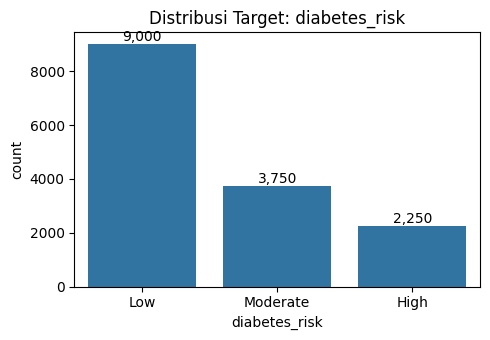

In [71]:
target_count = df[TARGET].value_counts().reindex(TARGET_ORDER)
target_pct = (target_count / len(df) * 100).round(1)
print(pd.DataFrame({"jumlah": target_count, "persen": target_pct}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x=TARGET, order=TARGET_ORDER, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribusi Target: diabetes_risk")
plt.tight_layout()
plt.show()

**Interpretasi**: Low 9.000 (60%), Moderate 3.750 (25%), High 2.250 (15%). Angkanya persis 60/25/15, sesuai dengan dataset sintetis yang proporsi kelasnya ditetapkan pembuatnya. Imbalance moderat (Low : High sekitar 4 : 1). Menebak "Low" untuk semua pasien sudah memberi accuracy 60%, jadi accuracy saja menyesatkan. Gunakan macro F1 dan recall per kelas, serta stratified split.

#### Univariate: Fitur Numerik

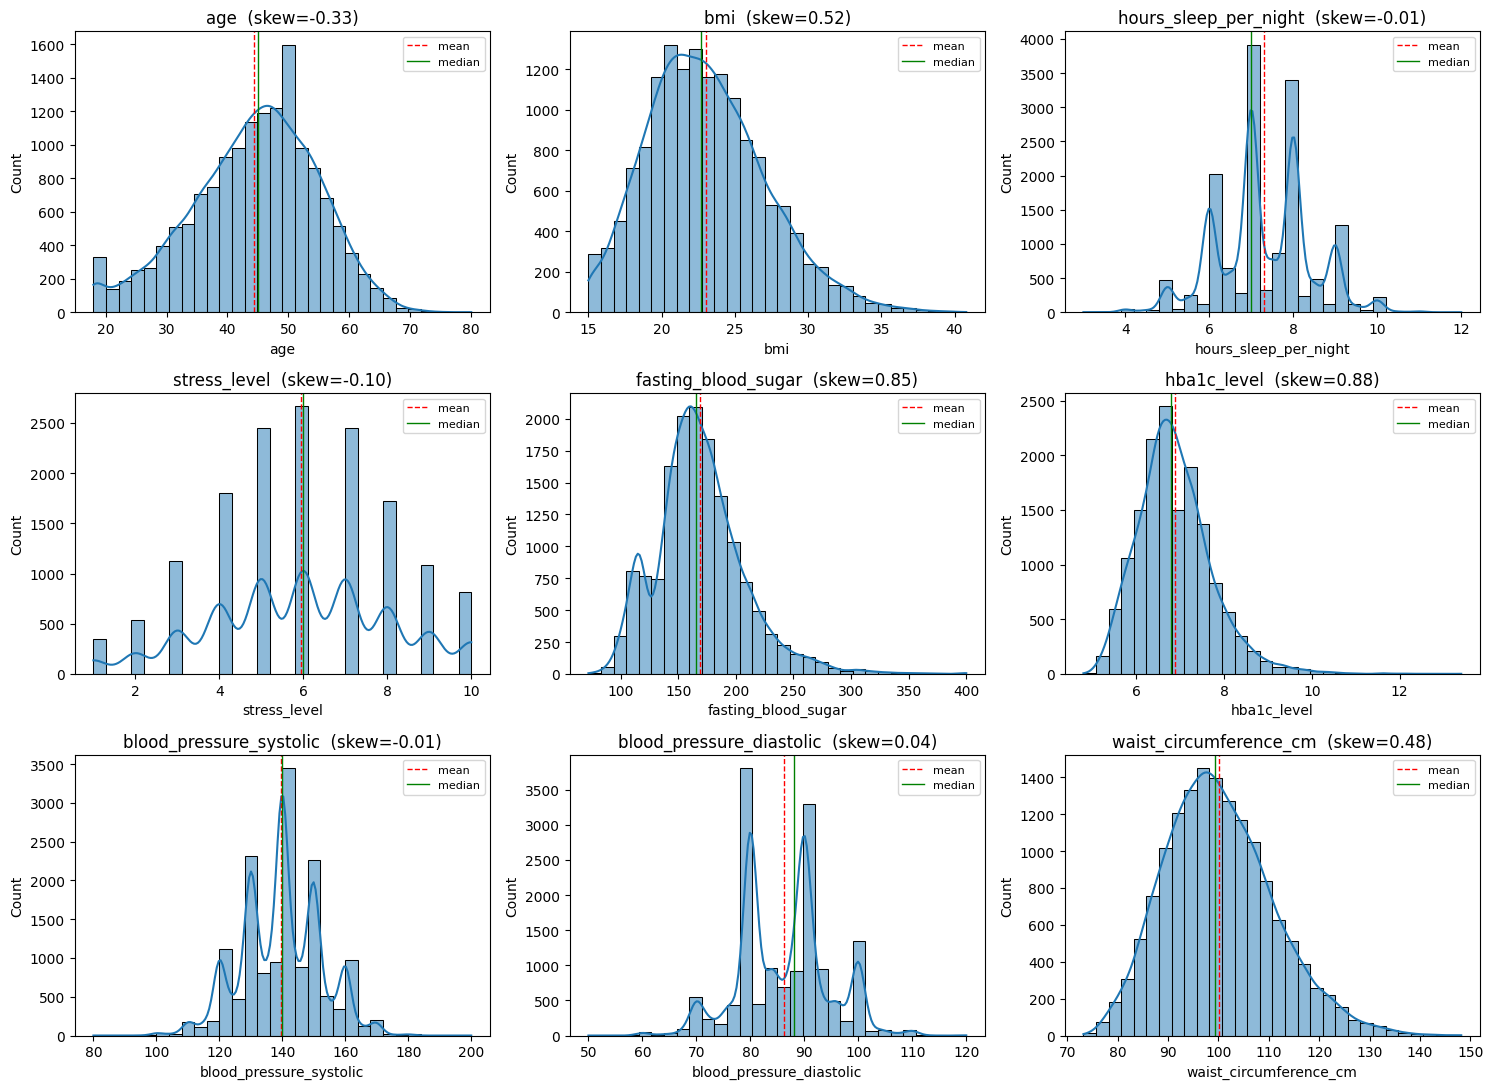

In [72]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, bins=30)
    ax.axvline(df[col].mean(), color="red", ls="--", lw=1, label="mean")
    ax.axvline(df[col].median(), color="green", ls="-", lw=1, label="median")
    ax.set_title(f"{col}  (skew={df[col].skew():.2f})")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi**: Miring ke kanan: hba1c_level (skew 0,88) dan fasting_blood_sugar (0,85); agak miring: bmi (0,52) dan waist_circumference_cm (0,48). Cukup simetris (|skew| sekitar 0,1 atau kurang): hours_sleep_per_night, stress_level, dan kedua tekanan darah. age sedikit miring ke kiri (-0,33). Skew tergolong moderat, jadi transformasi tidak wajib. Scaling tetap perlu untuk model berbasis jarak atau gradien.

#### Univariate: Fitur Kategorikal

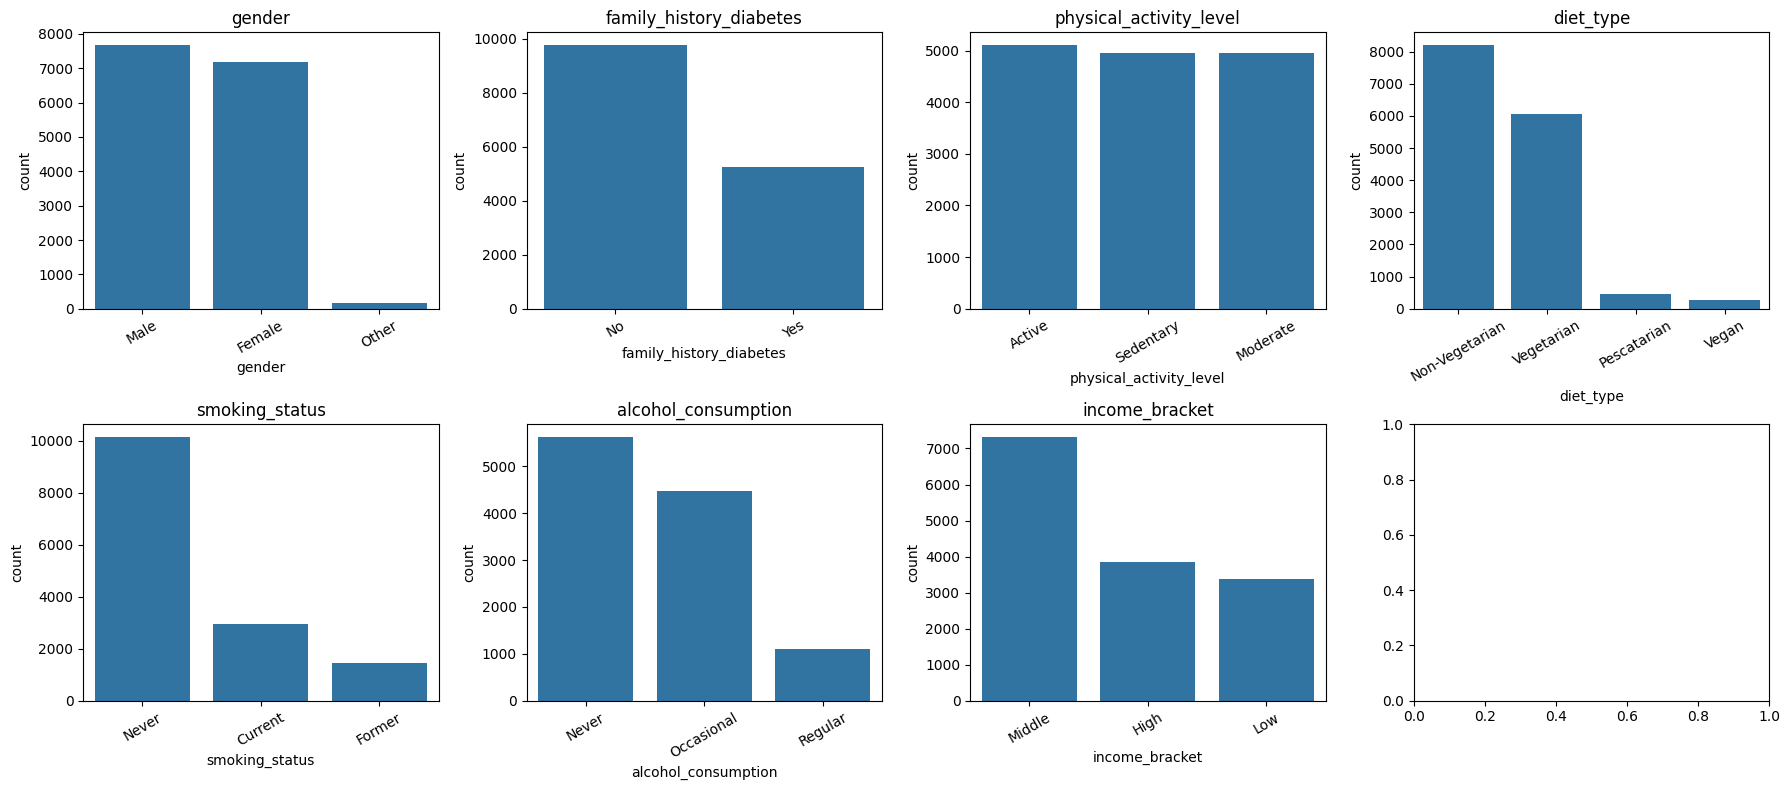

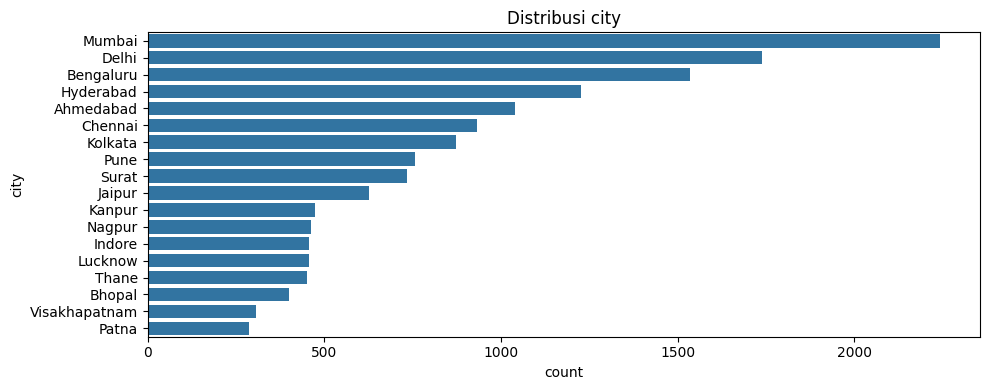

In [73]:
plot_cols = [c for c in cat_cols if c != "city"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), plot_cols):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.countplot(data=df, y="city", order=df["city"].value_counts().index)
plt.title("Distribusi city")
plt.tight_layout()
plt.show()

**Interpretasi**: gender: Male 51%, Female 48%, Other hanya 1% (153 baris). diet_type: Non-Vegetarian 55%, Vegetarian 40,5%, Pescatarian 3% dan Vegan 1,9%. smoking_status: Never 70%, Current 20%, Former 10%. alcohol_consumption: Never 50%, Occasional 40%, Regular 10%. income_bracket: Middle 50%, High 26%, Low 23%. city: 18 kota, dari 288 baris (Patna) sampai 2.243 baris (Mumbai). Persentase dihitung dari baris yang terisi. Kategori yang sangat kecil (Other, Pescatarian, Vegan) berisiko tidak stabil saat modeling.

### Outlier (Metode IQR)

In [89]:
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, low, high, n_out, n_out / len(df) * 100])

outlier_df = pd.DataFrame(rows, columns=["kolom", "batas_bawah", "batas_atas", "jumlah_outlier", "persen"])
outlier_df.sort_values("persen", ascending=False).round(2)

,kolom,batas_bawah,batas_atas,jumlah_outlier,persen
4,fasting_blood_sugar,79.00,255.00,432,2.88
2,hours_sleep_per_night,4.75,9.95,360,2.40
5,hba1c_level,4.80,8.80,355,2.37
7,blood_pressure_diastolic,65.00,105.00,213,1.42
8,waist_circumference_cm,70.90,128.50,167,1.11
1,bmi,11.85,33.85,153,1.02
6,blood_pressure_systolic,100.00,180.00,11,0.07
0,age,17.00,73.00,3,0.02
3,stress_level,-0.50,11.50,0,0.00


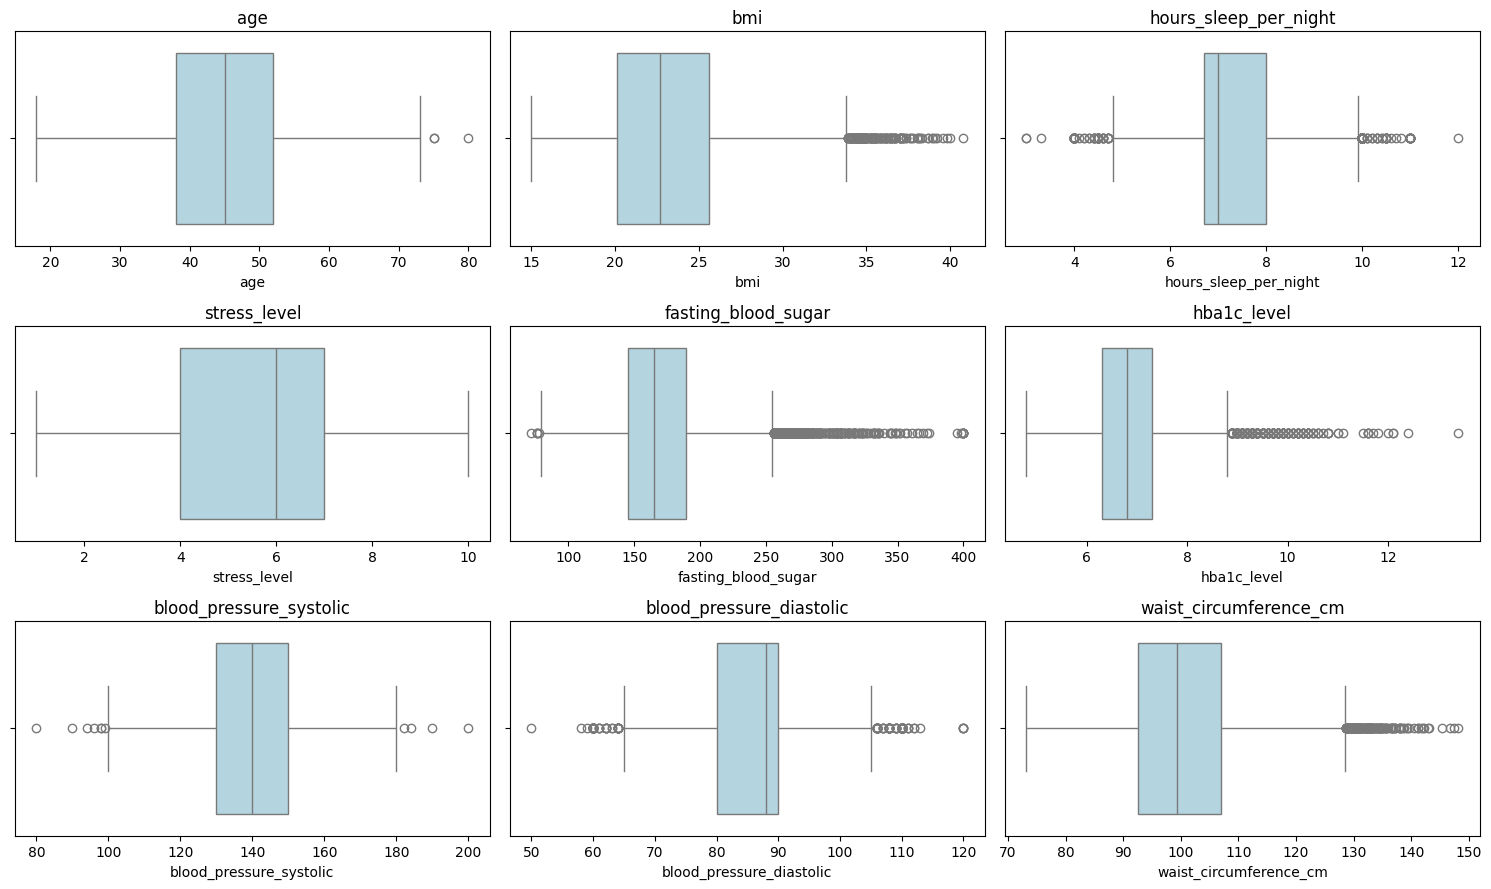

In [74]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax, color="lightblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Interpretasi**: Outlier terbanyak ada di fasting_blood_sugar (432 baris, 2,88%), hours_sleep_per_night (2,40%), dan hba1c_level (2,37%); semua kolom di bawah 3%. Nilainya masih masuk akal secara fisiologis (tidur 3 atau 12 jam, FBS tinggi pada pasien berisiko), jadi belum ada alasan membuangnya. Batas IQR stress_level (-0,5 sampai 11,5) tidak bermakna karena skalanya 1–10. Bila perlu, tangani dengan RobustScaler atau capping.

### EDA: Bivariate

### Fitur numerik vs target 

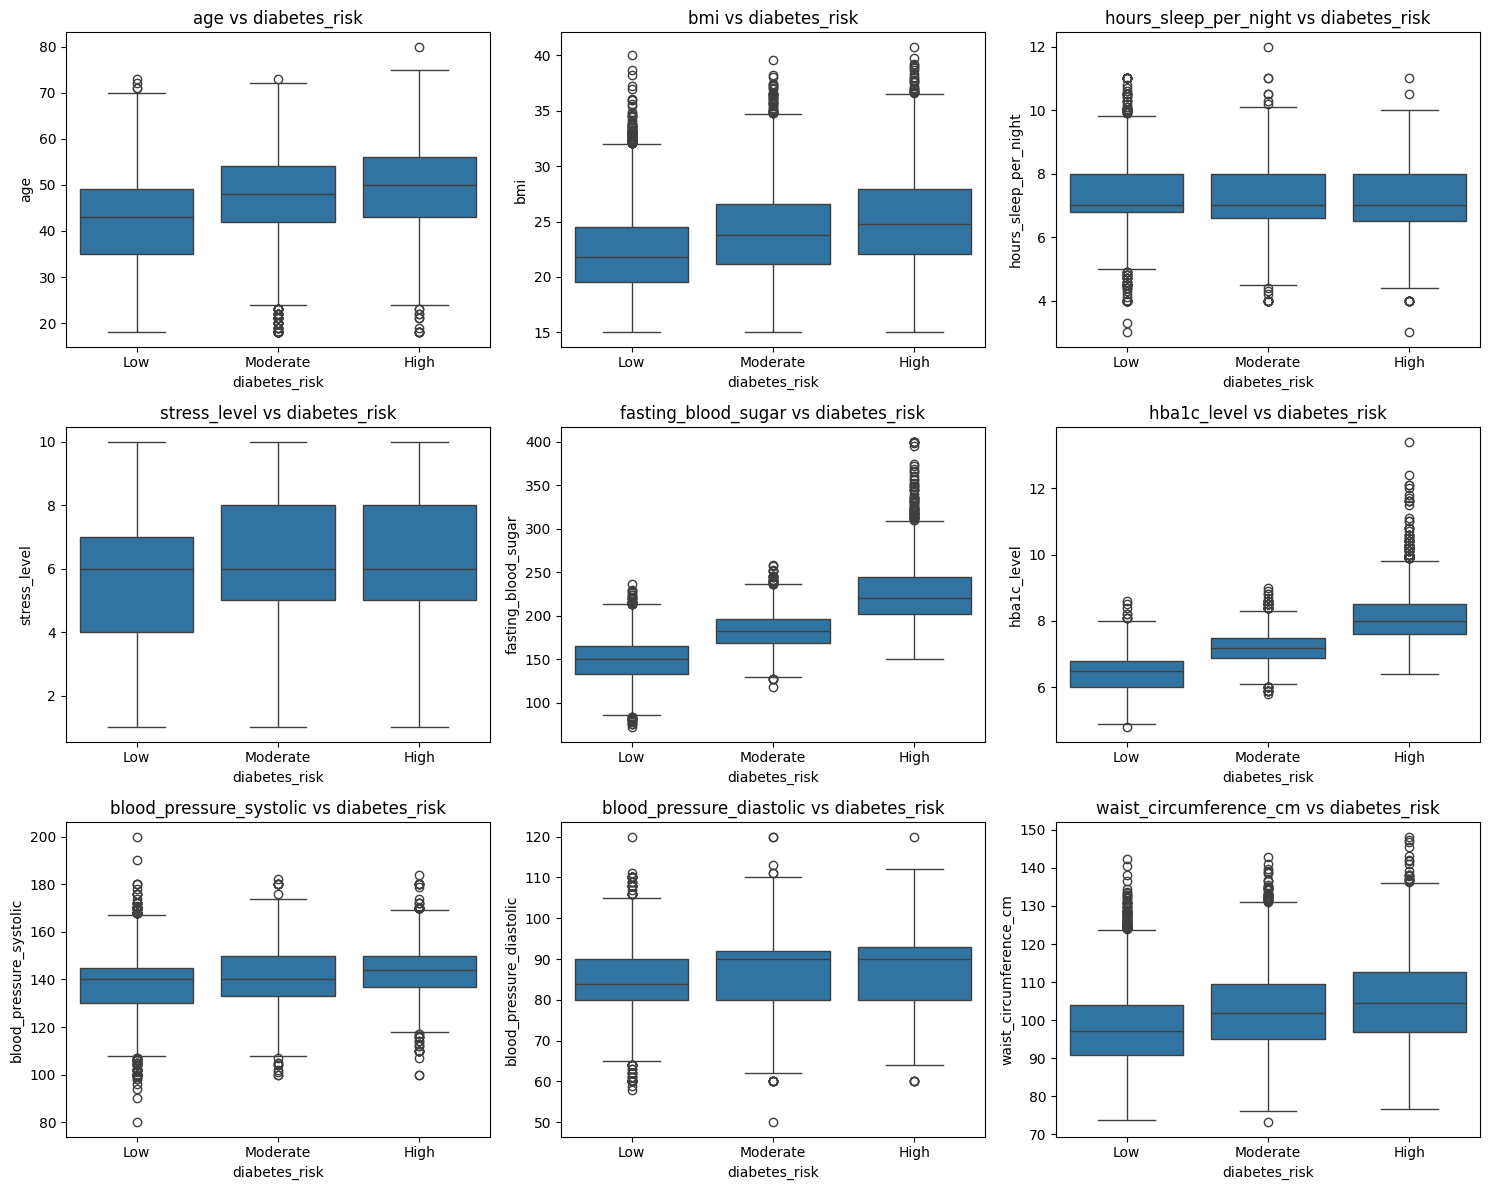

In [76]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, order=TARGET_ORDER, ax=ax)
    ax.set_title(f"{col} vs {TARGET}")
plt.tight_layout()
plt.show()

In [90]:
# Rata-rata tiap fitur per kelas target
display(df.groupby(TARGET)[num_cols].mean().loc[TARGET_ORDER].T.round(2))
display(df.groupby(TARGET)[["fasting_blood_sugar", "hba1c_level"]].agg(["min", "max"]).loc[TARGET_ORDER])

diabetes_risk,Low,Moderate,High
age,41.87,47.34,49.17
bmi,22.13,24.06,25.11
hours_sleep_per_night,7.35,7.27,7.23
stress_level,5.76,6.18,6.27
fasting_blood_sugar,148.30,183.32,226.54
hba1c_level,6.43,7.20,8.14
blood_pressure_systolic,137.32,141.99,144.05
blood_pressure_diastolic,85.11,87.63,88.56
waist_circumference_cm,97.92,102.68,105.25


fasting_blood_sugar      hba1c_level      
                              min  max         min   max
diabetes_risk                                           
Low                            72  236         4.8   8.6
Moderate                      118  258         5.8   9.0
High                          150  400         6.4  13.4

In [91]:
res = []
for col in num_cols:
    groups = [df.loc[df[TARGET] == k, col] for k in TARGET_ORDER]
    f, p = stats.f_oneway(*groups)
    grand = df[col].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((df[col] - grand) ** 2).sum()
    res.append([col, f, ss_between / ss_total, p, stats.kruskal(*groups)[1]])

anova_df = pd.DataFrame(res, columns=["fitur", "F_stat", "eta_sq", "p_anova", "p_kruskal"]).sort_values("eta_sq", ascending=False)
anova_df["p_anova"] = anova_df["p_anova"].map(lambda x: f"{x:.1e}")
anova_df["p_kruskal"] = anova_df["p_kruskal"].map(lambda x: f"{x:.1e}")
anova_df.round(3)

,fitur,F_stat,eta_sq,p_anova,p_kruskal
4,fasting_blood_sugar,9050.665,0.547,0.0e+00,0.0e+00
5,hba1c_level,8807.507,0.540,0.0e+00,0.0e+00
0,age,716.367,0.087,7.3e-298,1.9e-290
1,bmi,699.500,0.085,3.6e-291,1.1e-259
8,waist_circumference_cm,593.376,0.073,9.7e-249,3.1e-221
6,blood_pressure_systolic,367.591,0.047,1.4e-156,1.5e-151
7,blood_pressure_diastolic,226.182,0.029,1.7e-97,1.3e-92
3,stress_level,83.358,0.011,1.0e-36,4.2e-36
2,hours_sleep_per_night,14.527,0.002,5.0e-07,2.6e-07


**Interpretasi**: fasting_blood_sugar dan hba1c_level paling jelas bergeser naik dari Low ke High (FBS 148,3 -> 183,3 -> 226,5; HbA1c 6,43 -> 7,20 -> 8,14) dan punya efek sangat besar (η² = 0,547 dan 0,540). Efek sedang pada age (0,087; 41,9 -> 47,3 -> 49,2), bmi (0,085; 22,1 -> 24,1 -> 25,1), dan waist_circumference_cm (0,073), serta efek kecil pada tekanan darah dan stress_level. hours_sleep_per_night praktis tidak membedakan kelas (η² = 0,002; 7,35 -> 7,27 -> 7,23 jam).

Namun kelasnya masih tumpang tindih: FBS Low 72–236, Moderate 118–258, High 150–400; HbA1c Low 4,8–8,6, Moderate 5,8–9,0, High 6,4–13,4. Tidak ada satu batas angka yang memisahkan kelas dengan bersih. Kruskal-Wallis memberi kesimpulan yang sama dengan ANOVA, jadi hasil tidak bergantung pada asumsi normalitas. Nilai p yang tertulis 0,0e+00 berarti sangat kecil sampai terbaca nol oleh komputer, bukan benar-benar nol.

### Ambang Klinis vs Kelas Risiko

In [93]:
flag = pd.DataFrame({
    "FBS >= 126":      df["fasting_blood_sugar"] >= 126,
    "HbA1c >= 6.5":    df["hba1c_level"] >= 6.5,
    "BMI >= 25":       df["bmi"] >= 25,
    "BMI >= 30":       df["bmi"] >= 30,
    "Sistolik >= 140": df["blood_pressure_systolic"] >= 140,
})
(flag.groupby(df[TARGET]).mean().loc[TARGET_ORDER] * 100).round(1)

,FBS >= 126,HbA1c >= 6.5,BMI >= 25,BMI >= 30,Sistolik >= 140
diabetes_risk,,,,,
Low,78.8,50.2,21.3,2.7,51.5
Moderate,100.0,95.4,39.0,8.5,67.3
High,100.0,100.0,49.1,13.3,72.5


**Interpretasi**: Ini temuan paling penting di seluruh EDA. Hampir semua pasien Moderate dan High punya FBS ≥126 (>99,9%), dan HbA1c ≥6,5 pada 95,4% Moderate serta >99,9% High. Namun 78,8% pasien Low juga melewati FBS 126 dan 50,2% melewati HbA1c 6,5, padahal secara klinis itu sudah rentang diabetes. Jadi ambang klinis bersifat perlu tetapi tidak cukup: FBS di bawah 126 hampir pasti Low (1.907 dari 1.908 pasien), tetapi di atasnya kelasnya bisa apa saja. Label diabetes_risk bukan diagnosis klinis nyata dan tidak mengikuti ambang klinis, konsisten dengan dataset sintetis. Inilah alasan kelas Moderate sulit dipisahkan dan performa model punya batas atas. Pola tetap naik dari Low ke High (contoh BMI ≥25: 21% -> 39% -> 49%).

Catatan: tekanan darah memakai sistolik ≥140 (hipertensi stage 2 menurut AHA/ACC), bukan ≥130/80 (stage 1), karena di data ini 96,1% pasien sudah ≥130/80 sehingga ambang itu tidak membedakan apa-apa (lihat section 3). Sebutkan alasan ini di laporan agar tidak dianggap tidak konsisten.

### Fitur Kategorik vs Target

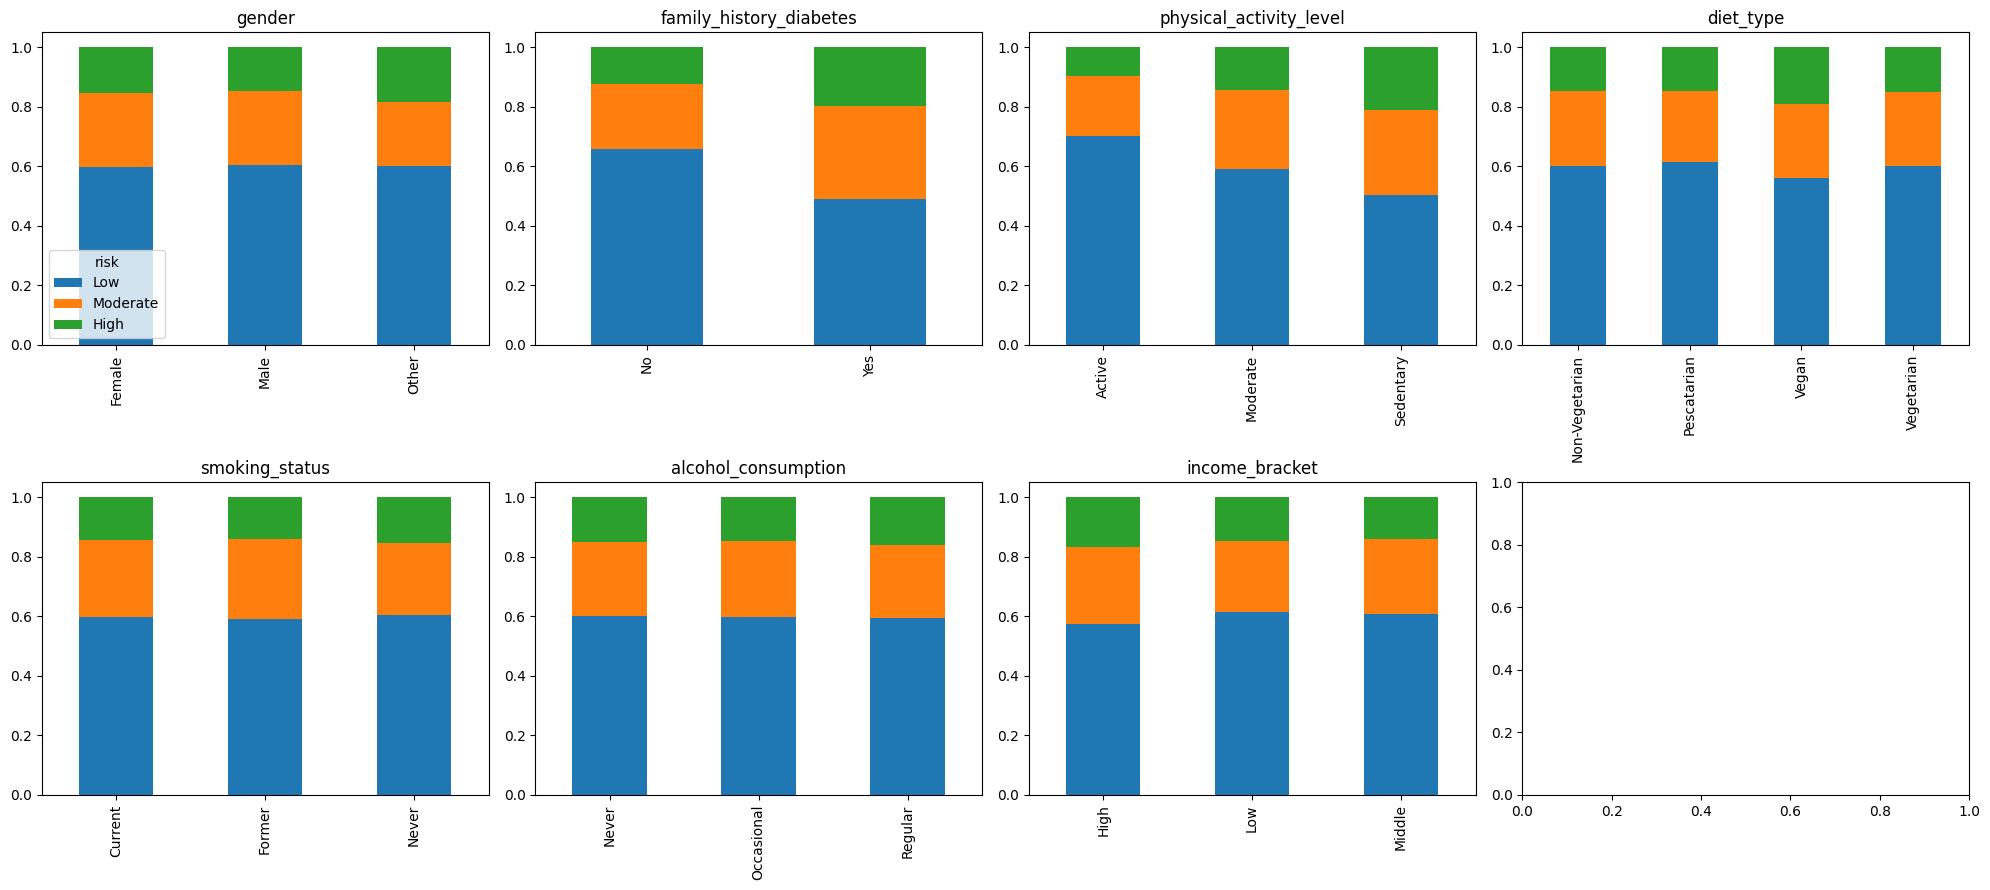

In [79]:
plot_cats = [c for c in cat_cols if c != "city"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), plot_cats):
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")[TARGET_ORDER]
    ct.plot(kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(col); ax.set_xlabel("")
axes.ravel()[0].legend(title="risk")
plt.tight_layout()
plt.show()

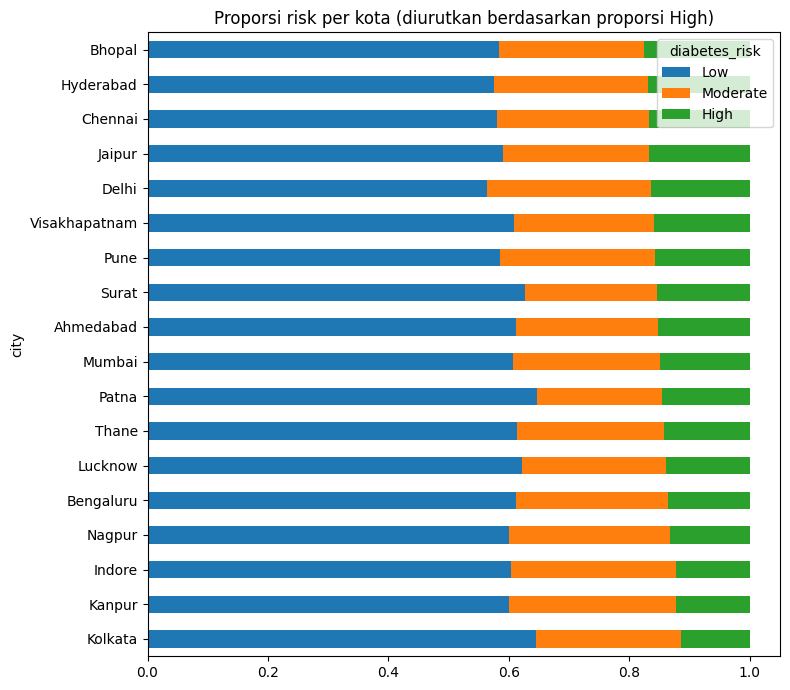

In [80]:
ct = pd.crosstab(df["city"], df[TARGET], normalize="index")[TARGET_ORDER].sort_values("High")
ct.plot(kind="barh", stacked=True, figsize=(8, 7))
plt.title("Proporsi risk per kota (diurutkan berdasarkan proporsi High)")
plt.tight_layout(); plt.show()

In [94]:
res = []
for col in cat_cols:
    tmp = df[[col, TARGET]].dropna()
    ct = pd.crosstab(tmp[col], tmp[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    res.append([col, chi2, p, v])

chi_df = pd.DataFrame(res, columns=["fitur", "chi2", "p_value", "cramers_v"]).sort_values("cramers_v", ascending=False)
chi_df["p_value"] = chi_df["p_value"].map(lambda x: f"{x:.2e}")
chi_df.round(3)

,fitur,chi2,p_value,cramers_v
2,family_history_diabetes,402.297,4.39e-88,0.164
3,physical_activity_level,453.489,7.65e-97,0.123
1,city,53.474,1.80e-02,0.042
7,income_bracket,20.264,4.43e-04,0.026
5,smoking_status,5.342,2.54e-01,0.014
4,diet_type,4.702,5.83e-01,0.013
0,gender,2.660,6.16e-01,0.009
6,alcohol_consumption,1.326,8.57e-01,0.008


**Interpretasi**: Hanya dua fitur kategorikal yang punya hubungan terlihat. family_history_diabetes (V = 0,164): Yes -> Low 49,1% dan High 19,7%; No -> Low 65,9% dan High 12,5%. physical_activity_level (V = 0,123): Active -> Low 70,1% dan High 9,8%; Sedentary -> Low 50,5% dan High 21,0%.

Sisanya lemah: city 0,042 (p = 0,018), income_bracket 0,026 (p = 0,0004; signifikan tetapi efeknya sangat kecil), sedangkan smoking_status, diet_type, gender, dan alcohol_consumption punya V sekitar 0,01 dengan p di atas 0,05, jadi tidak ada hubungan yang terbukti dengan target. Proporsi High per kota hanya berkisar 11,4% sampai 17,5% (rata-rata 14,8%), dan kota kecil (288 baris) wajar lebih goyang; one-hot 18 level akan menambah banyak kolom untuk sinyal lemah. Dibandingkan fitur numerik, semua fitur kategorikal berefek kecil (V maksimum 0,164), jadi prediksi akan didominasi fitur numerik klinis.

### Korelasi dan Multikolinearitas

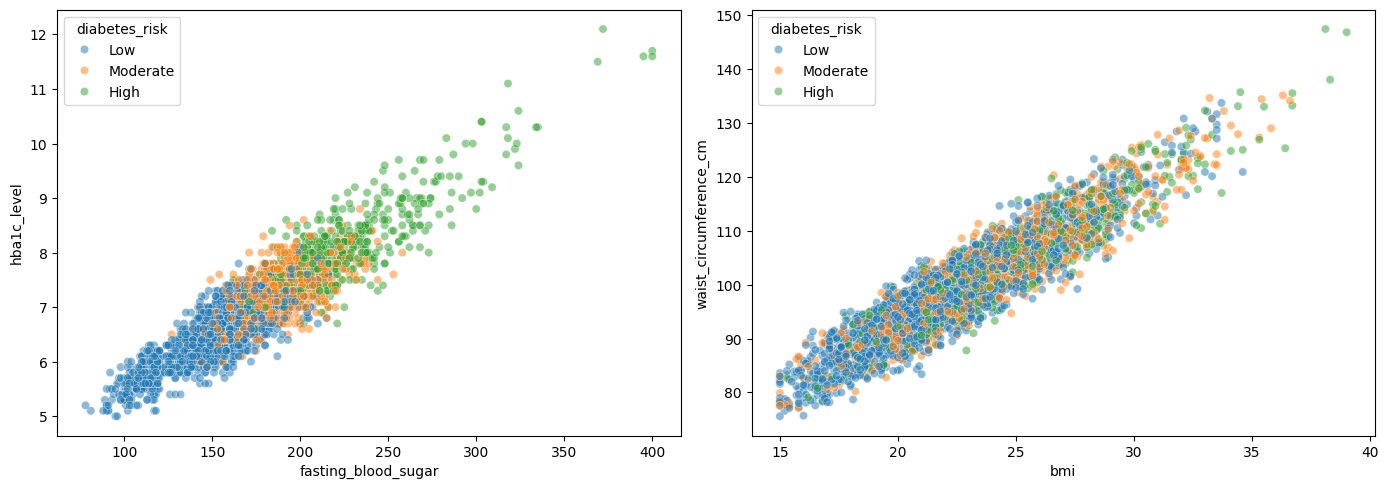

In [82]:
# Visualisasi pasangan berkorelasi tinggi (sampel 3000 baris biar ringan)
s = df.sample(3000, random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=s, x="fasting_blood_sugar", y="hba1c_level", hue=TARGET, hue_order=TARGET_ORDER, alpha=0.5, ax=axes[0])
sns.scatterplot(data=s, x="bmi", y="waist_circumference_cm", hue=TARGET, hue_order=TARGET_ORDER, alpha=0.5, ax=axes[1])
plt.tight_layout()
plt.show()

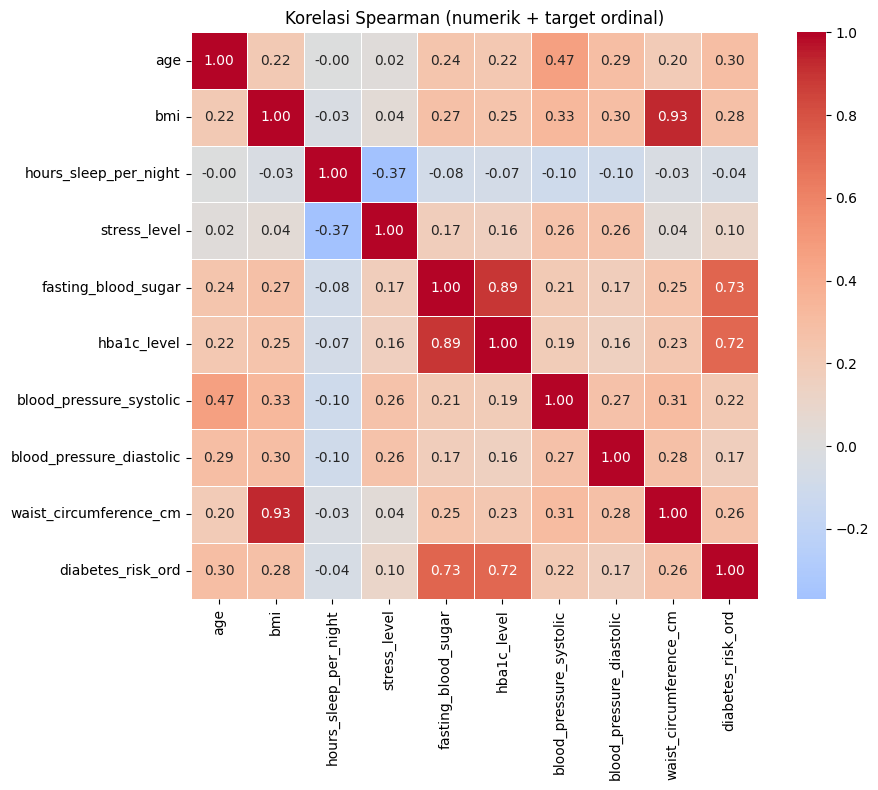

,korelasi_dgn_target
fasting_blood_sugar,0.731639
hba1c_level,0.719728
age,0.297530
bmi,0.281974
waist_circumference_cm,0.260197
blood_pressure_systolic,0.215134
blood_pressure_diastolic,0.167809
stress_level,0.103048
hours_sleep_per_night,-0.044952


In [95]:
df_corr = df[num_cols].copy()
df_corr["diabetes_risk_ord"] = df[TARGET].map({"Low": 0, "Moderate": 1, "High": 2})

corr = df_corr.corr(method="spearman")   # spearman: aman buat data skewed & ordinal
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Korelasi Spearman (numerik + target ordinal)")
plt.tight_layout()
plt.show()

corr["diabetes_risk_ord"].drop("diabetes_risk_ord").sort_values(key=abs, ascending=False).to_frame("korelasi_dgn_target")

**Interpretasi**: Korelasi dengan target (Low = 0, Moderate = 1, High = 2): FBS 0,73, HbA1c 0,72, usia 0,30, BMI 0,28, lingkar pinggang 0,26, sistolik 0,22, diastolik 0,17, stress 0,10, tidur -0,04. Dua pasangan fitur hampir redundan: BMI dan lingkar pinggang (0,93) serta FBS dan HbA1c (0,89). Pada scatter plot keduanya membentuk pita linear, dan kelas High terkumpul di kanan atas. Ini tidak mengganggu model berbasis pohon, tetapi menjadi masalah bagi Logistic Regression atau SVM. Catatan: pengkodean target ordinal mengasumsikan jarak Low -> Moderate sama dengan Moderate -> High.

### Ringkasan Temuan

1. **Kualitas data:** tidak ada duplikat; ada 2 baris tekanan darah janggal (diastolik ≥ sistolik); BMI menumpuk di 15,0 (127 baris). Drop atau cek manual 2 baris tersebut.

2. **Missing value:** alcohol_consumption 25,25% (terkait gender dan usia di atas 60, tidak terkait target); smoking_status dan income_bracket sekitar 3%. Jangan dropna; isi alcohol dengan "Unknown"; imputer di-fit hanya di data train.

3. **Target:** Low 60% / Moderate 25% / High 15% (persis). Stratified split, macro F1, class_weight atau SMOTE di data train.

4. **Fitur kuat:** fasting_blood_sugar dan hba1c_level (η² sekitar 0,54; korelasi Spearman 0,73 dan 0,72). Akan jadi fitur dominan di model.

5. **Fitur sedang:** age, bmi, waist_circumference_cm, family_history_diabetes, physical_activity_level. Pertahankan.

6. **Fitur lemah:** hours_sleep_per_night, stress_level, gender, diet_type, smoking_status, alcohol_consumption, income_bracket, city. Kandidat dibuang, tapi putuskan lewat uji di model.

7. **Outlier:** maksimum 2,88% per kolom dan nilainya masuk akal. Jangan dibuang; pakai RobustScaler bila perlu.

8. **Kolinearitas:** BMI–lingkar pinggang 0,93; FBS–HbA1c 0,89. Regularisasi, atau pilih salah satu dari tiap pasangan untuk model linear.

9. **Kualitas label:** 78,8% pasien Low juga punya FBS ≥ 126 dan kelas saling tumpang tindih. Performa model punya batas atas; Moderate paling sulit dipisahkan.